# 01 · Explore the data

Before looking for patterns you need to **know the data** and check it is clean. If the data is wrong, everything after it is wrong too.

The data lives in `data/BTC.csv`: a **CSV**, a table saved as plain text (like a simple spreadsheet). Each row is one hour, with three columns:
- `time`: the hour.
- `close`: the price at the close of that hour.
- `fundingRate`: the **funding**, the payment made every hour between those betting on a rise (*longs*) and those betting on a fall (*shorts*). When it is **positive**, longs pay shorts: more people are betting on a rise than the market "needs".

## 1. Load the table
`pd.read_csv` reads the file into a pandas table (a *DataFrame*). `head()` shows the first rows.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (11, 4)

COINS = ["HYPE", "BTC", "ETH", "SOL"]
COIN = "HYPE"   # Hyperliquid's own token; change to "BTC", "ETH" or "SOL" to look at another coin
df = pd.read_csv(f"../data/{COIN}.csv", parse_dates=["time"])
df.head()

,time,close,fundingRate
0,2026-04-07 02:00:00,36.372,NaN
1,2026-04-07 03:00:00,36.400,0.000005
2,2026-04-07 04:00:00,36.469,0.000013
3,2026-04-07 05:00:00,36.185,0.000013
4,2026-04-07 06:00:00,36.221,0.000010


## 2. Quick summary
`describe()` gives, for each column, how many values there are, the mean, the min, the max, etc. Check that the numbers make sense.

In [2]:
df.describe()

,time,close,fundingRate
count,4801,4801.000000,4800.000000
mean,2026-07-16 02:00:00,64.890320,0.000011
min,2026-04-07 02:00:00,35.878000,-0.000095
25%,2026-05-27 02:00:00,54.355000,0.000013
50%,2026-07-16 02:00:00,63.223000,0.000013
75%,2026-09-04 02:00:00,79.833000,0.000013
max,2026-10-24 02:00:00,97.553000,0.000181
std,NaN,16.329672,0.000013


## 3. Are there gaps?

A **gap** is an hour with no data. If many hours in a row are missing, the "next 8 hours" calculations go wrong.
- `isna().sum()`: how many empty values each column has.
- The second part looks for hours missing from the sequence (there should be one row every exact hour).

In [3]:
print("Empty values per column:")
print(df.isna().sum())

gaps = df["time"].diff().dropna()
print("\nGaps between rows other than 1 hour:", (gaps != pd.Timedelta("1h")).sum())

Empty values per column:
time           0
close          0
fundingRate    1
dtype: int64

Gaps between rows other than 1 hour: 0


## 4. Any odd values?

An **outlier** is a number far from normal: it can be a data error or a real event (a crash, a mass liquidation). Don't delete them blindly: look at them and decide.

Here we find the largest and smallest hourly return (how much the price changed from one hour to the next).

In [4]:
df["ret_1h"] = df["close"].pct_change()
print("Largest 1-hour rises:")
print(df.nlargest(3, "ret_1h")[["time", "close", "ret_1h"]])
print("\nLargest 1-hour drops:")
print(df.nsmallest(3, "ret_1h")[["time", "close", "ret_1h"]])

Largest 1-hour rises:
                    time   close    ret_1h
3233 2026-08-19 19:00:00  70.270  0.129271
3288 2026-08-22 02:00:00  80.718  0.053801
1651 2026-06-14 21:00:00  63.029  0.041957

Largest 1-hour drops:
                    time   close    ret_1h
1907 2026-06-25 13:00:00  58.720 -0.070607
1429 2026-06-05 15:00:00  57.802 -0.058308
922  2026-05-15 12:00:00  43.493 -0.048085


## 5. Plot the price
`plot` draws one column against another. The horizontal axis is time, the vertical one is price.

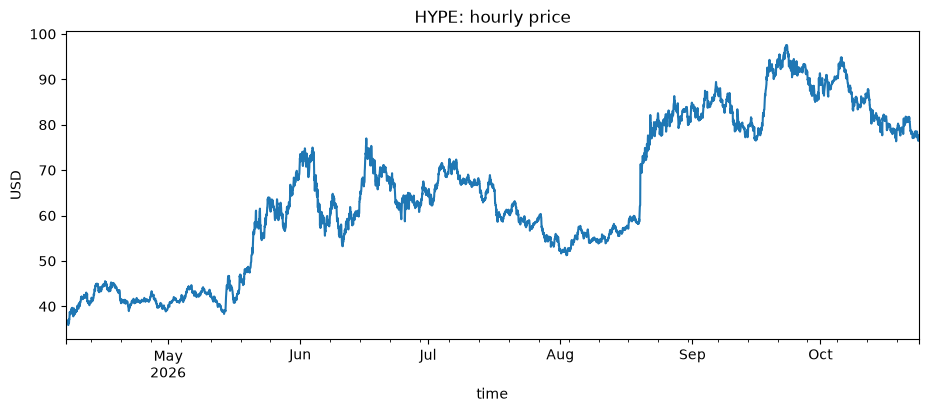

In [5]:
df.plot(x="time", y="close", title=f"{COIN}: hourly price", legend=False)
plt.ylabel("USD"); plt.show()

## 6. Plot the funding
Multiplied by 100 to read it in %. Check whether it is usually positive, whether it spikes, and when.

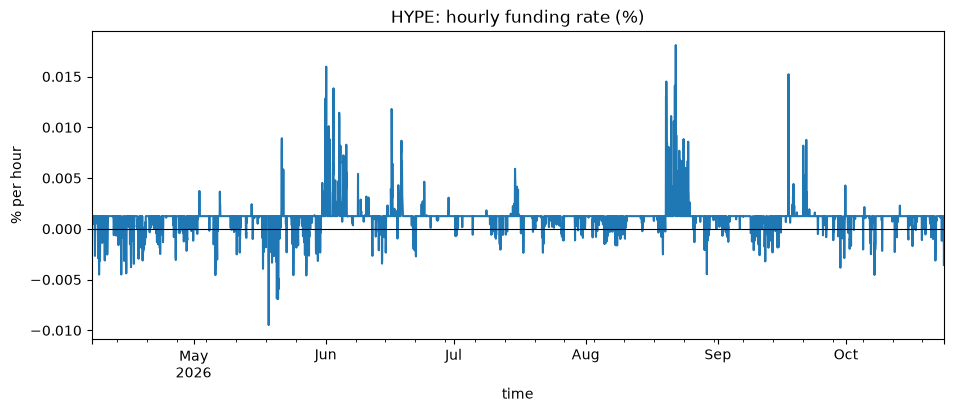

Hours with positive funding: 89%


In [6]:
(df.set_index("time")["fundingRate"] * 100).plot(title=f"{COIN}: hourly funding rate (%)")
plt.axhline(0, color="black", lw=0.8); plt.ylabel("% per hour"); plt.show()

print(f"Hours with positive funding: {(df.fundingRate > 0).mean():.0%}")

## Write down before moving on
- Are there gaps? How many?
- Any outlier? Was it a real event (look the date up on X or in the news)?
- Is funding usually positive or negative? Does it spike?

These answers go in the **Data** row of the README results.